In [1]:
import quarters_clean

In [3]:
investment_df = quarters_clean.pd.read_parquet("../data/quarter_investment_index_values.parquet")

In [5]:
investment_df.head()

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,1.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,21.33,1.07,NaN,1960,None,1
1,1.23,NaN,NaN,NaN,NaN,1.89,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,20.23,1.24,NaN,1961,None,1
2,1.24,NaN,NaN,NaN,NaN,2.01,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,22.18,1.28,NaN,1962,None,1
3,1.34,NaN,NaN,NaN,NaN,2.11,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,23.20,1.24,NaN,1963,None,1
4,1.46,NaN,NaN,NaN,NaN,2.54,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,26.33,1.60,NaN,1964,None,1


In [6]:
investment_df.tail()

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
257,119.24,26.87,33.03,377.41,7.64,138.00,12652.95,31244.21,3.02,1.58,...,351.05,49.97,951.16,438.67,966.48,96.80,14142.68,2020,None,4
258,137.21,28.62,34.14,415.75,7.27,155.82,16663.77,40851.39,3.13,1.03,...,394.04,52.53,974.94,673.67,1064.80,105.52,17224.76,2021,None,4
259,150.88,31.87,39.07,471.68,9.60,163.34,18622.28,53464.40,3.77,1.29,...,427.02,53.49,1060.31,1413.06,1154.60,115.28,15838.54,2022,None,4
260,166.24,31.96,39.58,456.88,11.62,168.28,18024.71,37473.07,4.41,1.31,...,450.79,53.42,1040.69,2723.62,1261.53,120.04,16259.69,2023,None,4
261,175.44,32.51,42.58,528.20,12.70,179.27,20073.88,54587.21,5.04,2.17,...,468.02,53.99,1091.88,3972.42,1318.78,125.68,18220.38,2024,None,4


In [7]:
quarters_clean.summarize_missing_by_country(investment_df)

,Missing Count,Missing %
Month,262,100.00
Malaysia,188,71.76
India,178,67.94
Colombia,160,61.07
Turkey,153,58.40
Brazil,145,55.34
Russia,143,54.58
Belgium,141,53.82
Israel,141,53.82
Ireland,141,53.82


**H1)** The previous output indicates that Malaysia will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [8]:
missing_entries = quarters_clean.get_missing_entries(investment_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1960,Austria,NaN
1,1,1960,Belgium,NaN
2,1,1960,Brazil,NaN
3,1,1960,Bulgaria,NaN
4,1,1960,Canada,NaN


In [9]:
malaysia_missing = quarters_clean.clean_country_missing_entries(missing_entries, "Malaysia")
malaysia_missing

,Quarter,Year,Country,Value
0,1,1960,Malaysia,NaN
1,2,1960,Malaysia,NaN
2,3,1960,Malaysia,NaN
3,4,1960,Malaysia,NaN
4,1,1961,Malaysia,NaN
...,...,...,...,...
183,4,2005,Malaysia,NaN
184,1,2006,Malaysia,NaN
185,2,2006,Malaysia,NaN
186,3,2006,Malaysia,NaN


The previous outputs show us that Malaysia has no values for the investment index from 1960 to 2006. Consequently, it has values in the range from 2007 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2006

In [23]:
clean_df1 = investment_df.copy()

In [24]:
clean_df1 = quarters_clean.filter_by_year(clean_df1, min_year=2006, max_year=2024)
clean_df1.head()

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,69.85,14.62,18.02,109.27,3.65,82.54,3892.94,27225.45,2.64,0.96,...,170.47,37.25,549.76,51.70,653.50,68.05,3529.35,2007,None,1
1,76.74,15.35,19.87,132.37,4.39,87.39,4620.71,27629.64,3.32,1.30,...,183.50,38.57,630.38,60.38,636.80,71.22,4612.56,2008,None,1
2,77.93,15.11,18.77,134.94,4.20,78.92,4686.98,29005.63,2.83,1.19,...,166.41,35.93,501.17,45.08,529.45,65.08,4264.29,2009,None,1
3,80.68,14.30,18.21,177.98,2.57,85.09,5769.86,30517.18,2.40,1.14,...,159.33,36.65,608.77,52.34,494.38,63.51,6134.29,2010,None,1
4,85.10,15.46,19.73,209.99,3.56,92.12,7076.82,36344.00,2.25,1.07,...,176.47,38.60,739.10,74.16,524.30,64.28,7019.16,2011,None,1


In [25]:
clean_df1.tail()

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
67,119.24,26.87,33.03,377.41,7.64,138.00,12652.95,31244.21,3.02,1.58,...,351.05,49.97,951.16,438.67,966.48,96.80,14142.68,2020,None,4
68,137.21,28.62,34.14,415.75,7.27,155.82,16663.77,40851.39,3.13,1.03,...,394.04,52.53,974.94,673.67,1064.80,105.52,17224.76,2021,None,4
69,150.88,31.87,39.07,471.68,9.60,163.34,18622.28,53464.40,3.77,1.29,...,427.02,53.49,1060.31,1413.06,1154.60,115.28,15838.54,2022,None,4
70,166.24,31.96,39.58,456.88,11.62,168.28,18024.71,37473.07,4.41,1.31,...,450.79,53.42,1040.69,2723.62,1261.53,120.04,16259.69,2023,None,4
71,175.44,32.51,42.58,528.20,12.70,179.27,20073.88,54587.21,5.04,2.17,...,468.02,53.99,1091.88,3972.42,1318.78,125.68,18220.38,2024,None,4


In [26]:
clean_df1.shape

(72, 58)

In [27]:
clean_df1 = clean_df1.sort_values(by=['Year', 'Quarter'])
clean_df1

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,69.85,14.62,18.02,109.27,3.65,82.54,3892.94,27225.45,2.64,0.96,...,170.47,37.25,549.76,51.70,653.50,68.05,3529.35,2007,None,1
18,81.72,16.12,19.69,119.17,4.05,93.61,4148.99,23203.72,2.89,1.08,...,206.09,40.35,588.35,61.93,656.20,70.67,3729.71,2007,None,2
36,77.98,16.51,18.74,129.92,4.46,97.41,4119.41,28411.63,2.86,1.11,...,176.08,40.26,578.84,63.47,652.40,68.16,4129.17,2007,None,3
54,85.56,18.05,23.58,131.18,5.80,94.65,4822.06,21662.20,3.07,1.31,...,226.04,42.42,593.54,70.46,647.18,73.42,4683.11,2007,None,4
1,76.74,15.35,19.87,132.37,4.39,87.39,4620.71,27629.64,3.32,1.30,...,183.50,38.57,630.38,60.38,636.80,71.22,4612.56,2008,None,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,166.24,31.96,39.58,456.88,11.62,168.28,18024.71,37473.07,4.41,1.31,...,450.79,53.42,1040.69,2723.62,1261.53,120.04,16259.69,2023,None,4
17,147.24,27.66,34.02,460.50,6.13,156.16,17534.41,83571.39,4.98,1.40,...,356.14,49.73,1037.54,2796.62,1284.63,121.41,16268.31,2024,None,1
35,178.13,29.37,37.70,484.96,8.19,175.32,17419.29,63385.25,5.26,1.64,...,408.93,51.77,937.30,3118.28,1300.28,123.24,17997.55,2024,None,2
53,164.86,29.29,35.50,526.79,9.36,183.48,18172.49,85515.04,4.94,1.67,...,371.32,51.43,1066.63,3569.30,1317.30,125.82,17985.95,2024,None,3


In [28]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Month,72,100.00
Russia,1,1.39
Australia,0,0.00
Austria,0,0.00
Bulgaria,0,0.00
Canada,0,0.00
Belgium,0,0.00
Brazil,0,0.00
Croatia,0,0.00
Cyprus,0,0.00


In [30]:
clean_df1["Russia"] = clean_df1["Russia"].ffill()

In [31]:
clean_df1 = clean_df1.drop(columns=["Month"])
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Australia,0,0.0
Austria,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0
Colombia,0,0.0
Croatia,0,0.0
Cyprus,0,0.0


In [32]:
clean_df1

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,69.85,14.62,18.02,109.27,3.65,82.54,3892.94,27225.45,2.64,0.96,...,76.65,170.47,37.25,549.76,51.70,653.50,68.05,3529.35,2007,1
18,81.72,16.12,19.69,119.17,4.05,93.61,4148.99,23203.72,2.89,1.08,...,82.21,206.09,40.35,588.35,61.93,656.20,70.67,3729.71,2007,2
36,77.98,16.51,18.74,129.92,4.46,97.41,4119.41,28411.63,2.86,1.11,...,76.20,176.08,40.26,578.84,63.47,652.40,68.16,4129.17,2007,3
54,85.56,18.05,23.58,131.18,5.80,94.65,4822.06,21662.20,3.07,1.31,...,86.87,226.04,42.42,593.54,70.46,647.18,73.42,4683.11,2007,4
1,76.74,15.35,19.87,132.37,4.39,87.39,4620.71,27629.64,3.32,1.30,...,78.08,183.50,38.57,630.38,60.38,636.80,71.22,4612.56,2008,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,166.24,31.96,39.58,456.88,11.62,168.28,18024.71,37473.07,4.41,1.31,...,77.38,450.79,53.42,1040.69,2723.62,1261.53,120.04,16259.69,2023,4
17,147.24,27.66,34.02,460.50,6.13,156.16,17534.41,83571.39,4.98,1.40,...,73.34,356.14,49.73,1037.54,2796.62,1284.63,121.41,16268.31,2024,1
35,178.13,29.37,37.70,484.96,8.19,175.32,17419.29,63385.25,5.26,1.64,...,78.46,408.93,51.77,937.30,3118.28,1300.28,123.24,17997.55,2024,2
53,164.86,29.29,35.50,526.79,9.36,183.48,18172.49,85515.04,4.94,1.67,...,75.00,371.32,51.43,1066.63,3569.30,1317.30,125.82,17985.95,2024,3


In [33]:
clean_df1 = clean_df1.reset_index(drop=True)
clean_df1

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,69.85,14.62,18.02,109.27,3.65,82.54,3892.94,27225.45,2.64,0.96,...,76.65,170.47,37.25,549.76,51.70,653.50,68.05,3529.35,2007,1
1,81.72,16.12,19.69,119.17,4.05,93.61,4148.99,23203.72,2.89,1.08,...,82.21,206.09,40.35,588.35,61.93,656.20,70.67,3729.71,2007,2
2,77.98,16.51,18.74,129.92,4.46,97.41,4119.41,28411.63,2.86,1.11,...,76.20,176.08,40.26,578.84,63.47,652.40,68.16,4129.17,2007,3
3,85.56,18.05,23.58,131.18,5.80,94.65,4822.06,21662.20,3.07,1.31,...,86.87,226.04,42.42,593.54,70.46,647.18,73.42,4683.11,2007,4
4,76.74,15.35,19.87,132.37,4.39,87.39,4620.71,27629.64,3.32,1.30,...,78.08,183.50,38.57,630.38,60.38,636.80,71.22,4612.56,2008,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,166.24,31.96,39.58,456.88,11.62,168.28,18024.71,37473.07,4.41,1.31,...,77.38,450.79,53.42,1040.69,2723.62,1261.53,120.04,16259.69,2023,4
68,147.24,27.66,34.02,460.50,6.13,156.16,17534.41,83571.39,4.98,1.40,...,73.34,356.14,49.73,1037.54,2796.62,1284.63,121.41,16268.31,2024,1
69,178.13,29.37,37.70,484.96,8.19,175.32,17419.29,63385.25,5.26,1.64,...,78.46,408.93,51.77,937.30,3118.28,1300.28,123.24,17997.55,2024,2
70,164.86,29.29,35.50,526.79,9.36,183.48,18172.49,85515.04,4.94,1.67,...,75.00,371.32,51.43,1066.63,3569.30,1317.30,125.82,17985.95,2024,3


In [34]:
clean_df2 = clean_df1.copy()

In [35]:
clean_df2 = quarters_clean.average_by_year(clean_df2)

   Year  Australia  Austria  Belgium    Brazil  Bulgaria    Canada      Chile  \
0  2007    78.7775  16.3250  20.0075  122.3850    4.4900   92.0525  4245.8500   
1  2008    87.3575  17.1725  21.2100  150.7125    6.0050   97.2250  5486.5275   
2  2009    86.2500  16.2225  19.6025  159.1675    5.0825   87.6275  4740.9575   
3  2010    89.9575  16.0700  19.9225  199.4825    4.1500   97.7200  6374.0100   
4  2011    97.0800  17.4950  21.5800  225.4825    4.2275  104.2725  7509.3925   

     Colombia  Croatia  ...  South-Africa  South-Korea    Spain    Sweden  \
0  25125.7500   2.8650  ...      111.5925    82142.900  80.4825  194.6700   
1  28260.7500   3.2425  ...      141.1250    89439.875  77.4725  203.4750   
2  27571.0000   2.7675  ...      136.1525    93013.925  62.1325  183.3800   
3  29771.9975   2.3150  ...      134.1550    99946.475  58.9050  195.7475   
4  35587.0000   2.2400  ...      148.1325   104706.175  53.8250  207.5300   

   Switzerland  Thailand   Turkey       USA  Unite

In [36]:
clean_df2

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,2007,78.7775,16.3250,20.0075,122.3850,4.4900,92.0525,4245.8500,25125.7500,2.8650,...,111.5925,82142.900,80.4825,194.6700,40.0700,577.6225,61.8900,652.3200,70.0750,4017.8350
1,2008,87.3575,17.1725,21.2100,150.7125,6.0050,97.2250,5486.5275,28260.7500,3.2425,...,141.1250,89439.875,77.4725,203.4750,41.0650,641.8150,66.8150,614.2150,70.3125,5082.0850
2,2009,86.2500,16.2225,19.6025,159.1675,5.0825,87.6275,4740.9575,27571.0000,2.7675,...,136.1525,93013.925,62.1325,183.3800,38.0125,558.0050,55.9275,506.4200,62.5150,5144.1425
3,2010,89.9575,16.0700,19.9225,199.4825,4.1500,97.7200,6374.0100,29771.9975,2.3150,...,134.1550,99946.475,58.9050,195.7475,39.3275,648.2925,71.9150,509.8275,64.5750,6871.4875
4,2011,97.0800,17.4950,21.5800,225.4825,4.2275,104.2725,7509.3925,35587.0000,2.2400,...,148.1325,104706.175,53.8250,207.5300,40.5575,730.3225,97.4450,549.5275,65.3075,7409.5675
5,2012,106.9800,18.1675,22.1325,249.3650,4.3650,111.8900,8692.8375,36832.2500,2.1500,...,159.9100,106403.450,48.4600,207.2450,42.2725,833.9225,106.9800,612.4800,67.5025,7190.5000
6,2013,106.8425,18.7175,21.8575,278.7375,4.3550,115.0275,9044.7900,39601.0025,2.1675,...,179.6850,109157.000,45.1250,208.9475,42.9225,819.5825,129.2200,653.4775,71.1100,7925.3875
7,2014,106.6775,18.9550,23.1250,287.1150,4.4325,121.6375,9422.1100,45780.4975,2.1075,...,189.1350,113147.525,46.8300,224.8700,43.9600,815.6925,147.6750,709.6100,77.1675,8908.4650
8,2015,105.8950,19.5825,24.0500,267.3500,4.6700,118.6825,10100.4625,47826.2500,2.1950,...,199.0350,120250.425,49.7350,245.8300,44.1075,842.7650,173.7025,745.4075,83.2450,9141.0500
9,2016,104.4575,20.7375,25.1950,243.3175,4.3900,115.3125,10180.3900,50029.0000,2.3250,...,207.5375,129337.475,51.0700,262.1550,44.9075,864.9725,191.1375,785.2400,89.1525,9761.4800


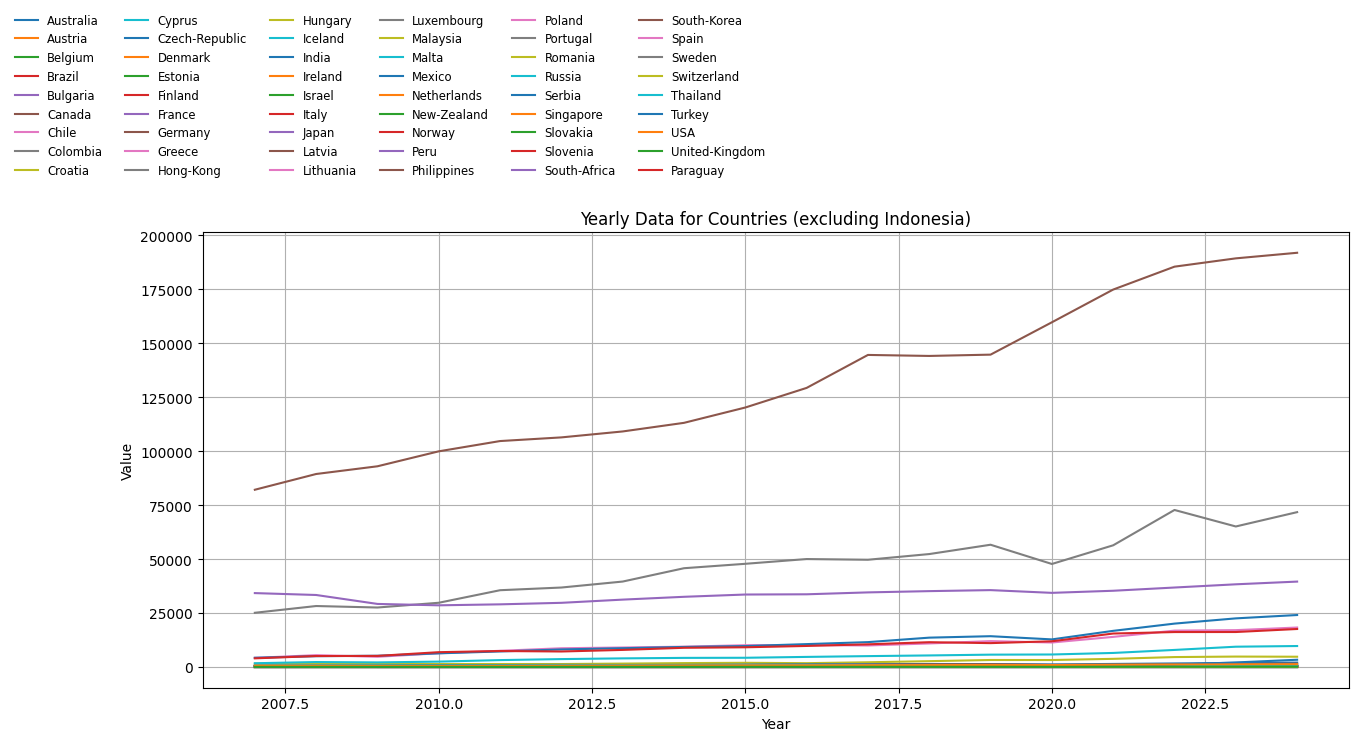

In [39]:
quarters_clean.plot_countries(clean_df2, exclude_country='Indonesia', legend_columns=6)

In [40]:
clean_df2.to_parquet("../data/clean_investment_index.parquet", index=False)